# NB24: Data IO Pipeline
## Reading, Writing, and Quality Control of RELIC Data

RELIC provides a unified data pipeline with bounded CF-1.8 variable metadata handling:
- `DataReader`: Load forcing/observation data (NetCDF4/3, HDF5, Zarr, CSV)
- `DataWriter`: Save datasets with CF variable metadata and descriptive global attributes
- `DiagnosticWriter`: Convert conservation diagnostics to datasets
- `IOHealthChecker`: Check I/O dependencies, formats, and codecs

**Key module**: `relic.data.io`

---

## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below are intended to use actual RELIC functors, the actual simulator or orchestration layer, and real validation pathways rather than notebook-defined pseudo-process equations.


## Learning Goals

- Exercise RELIC data readers, writers, standards, temporal scaling, and quality-control APIs with actual tensors and datasets.
- Verify CF metadata, temporal conservation, and gap-filling behavior inside the real data pipeline.
- Learn how DataIO summaries connect raw files to downstream simulator workflows.


In [1]:
# Use only the standard library so notebook execution stays self-contained on Windows.
import asyncio
if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

# --- Environment Guard (prevent OpenMP duplicate lib crash) ---
import os
import sys
import warnings
from pathlib import Path
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

DEFAULT_PROJECT_ROOT = Path(os.environ.get("RELIC_PROJECT_ROOT", Path.cwd())).resolve()

def locate_project_root() -> Path:
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents, DEFAULT_PROJECT_ROOT]
    for candidate in candidates:
        if (candidate / "relic").is_dir() and (candidate / "docs" / "source" / "architecture_overview.md").is_file():
            return candidate
    raise FileNotFoundError("Could not locate RELIC project root from the active notebook environment.")

PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import torch
import xarray as xr

from relic.data.io import DataIO
from relic.data.io.reader import DataReader, ReadConfig
from relic.data.io.writer import DataWriter, WriteConfig
from relic.data.io.diagnostic_writer import DiagnosticWriter
from relic.data.io.healthcheck import IOHealthChecker
from relic.data.standards.cf_conventions import CFConventions, CFAttributeSynchronizer
from relic.data import check_cf_variable_metadata, get_standard_units, standardize_variable_name

OUTPUT_DIR = PROJECT_ROOT / "tutorial" / "primary" / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
NB24_DATASET_PATH = OUTPUT_DIR / "24_cf_demo_dataset.nc"

print("[OK] Data IO modules loaded")
print(f"  project_root: {PROJECT_ROOT}")
print(f"  dataset path: {NB24_DATASET_PATH}")
print(f"  DataReader: {DataReader.__module__}")
print(f"  DataWriter: {DataWriter.__module__}")
print(f"  DiagnosticWriter: {DiagnosticWriter.__module__}")
print(f"  IOHealthChecker: {IOHealthChecker.__module__}")

[OK] Data IO modules loaded
  project_root: <RELIC_ROOT>
  dataset path: tutorial\primary\output\24_cf_demo_dataset.nc
  DataReader: relic.data.io.reader
  DataWriter: relic.data.io.writer
  DiagnosticWriter: relic.data.io.diagnostic_writer
  IOHealthChecker: relic.data.io.healthcheck


## 1. Data Reader Configuration

The `DataReader` uses `ReadConfig` to select the format and chunking, CF validation and
standardization, time processing, the variables to read, unit conversion, data
validation, and conversion to torch tensors (the fields are printed below).


In [2]:
# Examine ReadConfig structure
import inspect

print("=== ReadConfig Fields ===")
sig = inspect.signature(ReadConfig)
for name, param in sig.parameters.items():
    if name == 'self':
        continue
    default = param.default if param.default != inspect.Parameter.empty else 'REQUIRED'
    print(f"  {name}: {default}")

print("\n=== DataReader Public Methods ===")
for name in sorted(dir(DataReader)):
    if not name.startswith('_'):
        obj = getattr(DataReader, name, None)
        if callable(obj):
            print(f"  {name}()")


=== ReadConfig Fields ===
  format: DataFormat.AUTO
  chunks: None
  parallel: True
  cache_size: 128
  cf_validate: True
  cf_standardize: True
  strict_cf: False
  process_time: True
  time_bounds: True
  standard_calendar: False
  variables: None
  exclude_vars: None
  standard_names_only: False
  apply_unit_conversion: False
  target_units: None
  file_path: None
  validate_data: True
  fill_missing: False
  quality_flags: False
  to_torch: False
  torch_dtype: torch.float32
  torch_device: cpu

=== DataReader Public Methods ===
  read_dataset()
  read_tensors()


## 2. Data Writer and CF-1.8 Metadata

RELIC output uses NetCDF4 with CF-1.8 variable metadata (Eaton et al., 2020).
The `DataWriter`:
- Writes the explicit global attributes (`title`, `institution`, `source`, `comment`, `references`, `creation_date`) and appends a `history` entry, without declaring `Conventions`
- Checks each variable's `standard_name` against the bundled CF Standard Name Table v94 and its `units` against the canonical units; an unknown name or non-convertible units make the write fail (`WriteResult.validation_passed` is `False`, the reason is in `WriteResult.warnings`)
- Does not evaluate dataset-level CF conformance, so `WriteResult.cf_compliant` stays `False`

In [3]:
# Examine WriteConfig structure
print("=== WriteConfig Fields ===")
sig = inspect.signature(WriteConfig)
for name, param in sig.parameters.items():
    if name == 'self':
        continue
    default = param.default if param.default != inspect.Parameter.empty else 'REQUIRED'
    print(f"  {name}: {default}")

print("\n=== DataWriter Public Methods ===")
for name in sorted(dir(DataWriter)):
    if not name.startswith('_'):
        obj = getattr(DataWriter, name, None)
        if callable(obj):
            print(f"  {name}()")


=== WriteConfig Fields ===
  format: DataFormat.NETCDF4
  compression: CompressionType.ZSTD
  compression_level: 4
  chunks: None
  auto_chunk: True
  chunk_time_first: True
  cf_sync: True
  strict_cf: False
  add_bounds: True
  update_history: True
  title: None
  institution: None
  source: None
  comment: None
  references: None
  parallel: False
  validate_output: True
  create_dirs: True

=== DataWriter Public Methods ===
  prepare_dataset()
  write_dataset()
  write_tensors()


## 3. Diagnostic Writer

The `DiagnosticWriter` converts StateManager conservation summaries (`ConservationSummary`)
into an xarray dataset with registered diagnostic metadata and a CF time coordinate;
`export_diagnostics_to_netcdf` writes that dataset through `DataWriter`.

In [4]:
# Examine DiagnosticWriter
print("=== DiagnosticWriter Public Methods ===")
for name in sorted(dir(DiagnosticWriter)):
    if not name.startswith('_'):
        obj = getattr(DiagnosticWriter, name, None)
        if callable(obj):
            print(f"  {name}()")


=== DiagnosticWriter Public Methods ===
  convert_conservation_summary()
  convert_summaries_to_dataset()
  create_cf_time_coordinate()
  register_diagnostic_metadata()


## 4. IO Health Check

`IOHealthChecker` checks the I/O environment: dependencies, file-format and
compression support, the bounded single-variable CF metadata check, integration
with RELIC components, and I/O performance. `run_full_check()` runs all checks.

In [5]:
# Examine IOHealthChecker
print("=== IOHealthChecker Public Methods ===")
for name in sorted(dir(IOHealthChecker)):
    if not name.startswith('_'):
        obj = getattr(IOHealthChecker, name, None)
        if callable(obj):
            print(f"  {name}()")


=== IOHealthChecker Public Methods ===
  check_cf_metadata_subset()
  check_compression_support()
  check_dependencies()
  check_format_support()
  check_integration()
  check_performance()
  run_full_check()


## 5. CF-1.8 Standards API

RELIC's `relic.data.standards` module resolves CF standard names (table v94), their
canonical units, and validates the `standard_name`/`units` subset of one variable.


In [6]:
# References: RELIC architecture SSOT and the canonical owners used below.
# Mathematical expression: inspect current interfaces and verify returned quantities against their declarations.
# Parameter meanings: the named variables, fields and public owners below define this example.
# Units:
#   Forcing [K, kg m-2 s-1, W m-2]; actual Farquhar GPP [kg C m-2 s-1].
# Domain/constraints:
#   Synthetic bounded forcing with explicit CF metadata; variables_read is checked against returned data variables.
# Sign convention:
#   Precipitation is downward positive; GPP is positive uptake.
# === NB24 CF Convention Validation ===
# Demonstrate RELIC's CF-1.8 naming, synchronization, write, and read APIs.

from relic.scientific.biosphere.photosynthesis.farquhar import FarquharPhotosynthesis

cf_conventions = CFConventions()
cf_synchronizer = CFAttributeSynchronizer(strict_mode=False)

alias_display_map = {
    "temperature": "air_temperature",
    "precipitation": "precipitation_flux",
    "GPP": "gross_primary_productivity_of_biomass_expressed_as_carbon",
    "shortwave": "surface_downwelling_shortwave_flux_in_air",
}
print("=== CF-1.8 Convention Compliance ===")
print("Variable mapping (tutorial alias -> CF standard name):")
for alias, variable_name in alias_display_map.items():
    standard_name = cf_conventions.get_standard_name(variable_name)
    units = get_standard_units(standard_name)
    print(f"  {alias:12s} -> {standard_name:45s} units={units}")

TIME_UNITS_NB24 = "hours since 2001-07-01 00:00:00"
n_hours = 96
time_coord = (torch.arange(n_hours, dtype=torch.float32)).detach().cpu().tolist()
lat_coord = [-3.0, -2.5, -2.0]
lon_coord = [-55.5, -55.0, -54.5, -54.0]

hours = torch.arange(n_hours, dtype=torch.float32).view(n_hours, 1, 1)
hour_of_day = torch.remainder(hours, 24.0)
day_index = torch.div(torch.arange(n_hours, dtype=torch.int64), 24, rounding_mode="floor").view(n_hours, 1, 1)
daily_shortwave_factor_values = torch.tensor([0.92, 1.08, 0.84, 1.02], dtype=torch.float32)
daily_shortwave_factor = daily_shortwave_factor_values[day_index]
lat_offsets = torch.tensor(lat_coord, dtype=torch.float32).view(1, 3, 1)
lon_offsets = torch.tensor(lon_coord, dtype=torch.float32).view(1, 1, 4)

shortwave_shape = torch.exp(-0.5 * (((hour_of_day / 23.0) - 0.5) / 0.2) ** 2)
spatial_radiation_factor = (1.0 + 0.01 * (lat_offsets + 3.0)) * (1.0 + 0.02 * (lon_offsets + 55.0))
shortwave_tensor = 720.0 * daily_shortwave_factor * shortwave_shape * spatial_radiation_factor

air_temperature_tensor = (
    294.5
    + 4.2 * torch.sin(2.0 * torch.pi * (hour_of_day - 6.0) / 24.0)
    + 1.8 * (daily_shortwave_factor - torch.mean(daily_shortwave_factor_values))
    + 0.3 * (lat_offsets + 3.0)
    + 0.05 * (lon_offsets + 55.0)
)
precipitation_tensor = torch.zeros(n_hours, 3, 4, dtype=torch.float32)
precipitation_tensor[5:8] = 2.5e-4
precipitation_tensor[30:35] = 4.0e-4
precipitation_tensor[62:66] = 7.5e-4
precipitation_tensor[84:88] = 3.5e-4

photo_functor = FarquharPhotosynthesis(name="nb24_cf_farquhar", enable_gpu=False)
photo_state = {
    "air_temperature": air_temperature_tensor,
    "atmospheric_co2_ppm": torch.full_like(air_temperature_tensor, 410.0),
    "ppfd": torch.clamp(shortwave_tensor * 1.8, min=0.0, max=2500.0),
    "vcmax_scaling": torch.ones_like(air_temperature_tensor),
    "jmax_scaling": torch.ones_like(air_temperature_tensor),
    "water_stress_factor": torch.ones_like(air_temperature_tensor),
    "temperature_stress_factor": torch.ones_like(air_temperature_tensor),
    "ozone_stress_factor": torch.ones_like(air_temperature_tensor),
    "leaf_area_index": torch.full_like(air_temperature_tensor, 3.2),
    "vapor_pressure_deficit": torch.clamp(900.0 + 300.0 * torch.sin(2.0 * torch.pi * (hour_of_day - 12.0) / 24.0), min=200.0),
    "leaf_water_potential": torch.full_like(air_temperature_tensor, -0.35),
}
with warnings.catch_warnings(record=True) as captured_warnings:
    warnings.simplefilter("always")
    gpp_output = photo_functor(photo_state, time=0.0, dt=3600.0)
gpp_warnings = [str(item.message) for item in captured_warnings if "nb24_cf_farquhar" in str(item.message)]
gpp_tensor = gpp_output["gross_primary_productivity"].value.detach().to(dtype=torch.float32)


def build_cf_field(variable_name: str, tensor: torch.Tensor, long_name: str) -> xr.DataArray:
    standard_name = cf_conventions.get_standard_name(variable_name)
    units = get_standard_units(standard_name)
    metadata = {
        "standard_name": standard_name,
        "units": units,
        "coordinates": "time lat lon",
        "long_name": long_name,
    }
    attrs = cf_conventions.sync_variable_attributes(tensor, metadata)
    validation = check_cf_variable_metadata(attrs)
    if not validation.is_valid:
        raise ValueError(f"CF compliance failed for {variable_name}: {list(validation.issues)}")
    return xr.DataArray(
        tensor.detach().cpu().tolist(),
        dims=["time", "lat", "lon"],
        coords={"time": time_coord, "lat": lat_coord, "lon": lon_coord},
        attrs=attrs,
    )

cf_demo_ds = xr.Dataset(
    {
        "air_temperature": build_cf_field("air_temperature", air_temperature_tensor, "tutorial air temperature"),
        "precipitation_flux": build_cf_field("precipitation_flux", precipitation_tensor, "tutorial precipitation flux"),
        "surface_downwelling_shortwave_flux_in_air": build_cf_field(
            "surface_downwelling_shortwave_flux_in_air",
            shortwave_tensor,
            "tutorial shortwave forcing",
        ),
        "gross_primary_productivity_of_biomass_expressed_as_carbon": build_cf_field(
            "gross_primary_productivity_of_biomass_expressed_as_carbon",
            gpp_tensor,
            "gross primary productivity from actual Farquhar execution",
        ),
    },
    attrs=cf_conventions.create_global_attributes(
        title="NB24 CF demonstration dataset",
        institution="RELIC tutorial",
        source="In-notebook tensor dataset for RELIC Data IO walkthrough",
        history="Created in NB24 and synchronized through CFConventions",
    ),
)
cf_demo_ds["time"].attrs = {
    "standard_name": "time",
    "long_name": "time",
    "units": TIME_UNITS_NB24,
    "calendar": "gregorian",
    "axis": "T",
}
cf_demo_ds.attrs["comment"] = "This dataset is generated in the notebook to exercise RELIC Data IO APIs and uses actual RELIC Farquhar output for GPP."

nb24_writer = DataWriter(
    WriteConfig(
        title="NB24 CF demonstration dataset",
        institution="RELIC tutorial",
        source="NB24 in-notebook tensor dataset",
        comment="Written by RELIC DataWriter during notebook execution",
        references="CF-1.8 and RELIC data.io",
        add_bounds=False,
    )
)
nb24_reader = DataReader(
    ReadConfig(
        cf_validate=True,
        cf_standardize=True,
        process_time=False,
        time_bounds=False,
        validate_data=False,
    )
)
nb24_write_result = nb24_writer.write_dataset(cf_demo_ds, NB24_DATASET_PATH)
nb24_read_result = nb24_reader.read_dataset(NB24_DATASET_PATH)
nb24_dataset = nb24_read_result.data
readback_variables = list(nb24_dataset.data_vars)
nb24_compliance_summary = {}
for variable_name in nb24_dataset.data_vars:
    validation = cf_conventions.validate_cf_compliance(dict(nb24_dataset[variable_name].attrs))
    nb24_compliance_summary[variable_name] = {"is_valid": bool(validation.is_valid), "issues": list(validation.issues)}

print(f"\n[OK] Dataset written to: {nb24_write_result.output_path}")
print(f"  Variables written: {nb24_write_result.variables_written}")
print(f"  Coordinates added: {nb24_write_result.coordinates_added}")
print(f"  File size: {nb24_write_result.file_size} bytes")
print(f"  Read success: {nb24_read_result.success}")
# ReadResult.variables_read lists the data variables actually returned on every read.
assert set(nb24_read_result.variables_read) == set(readback_variables)
print(f"  Reader returned variables: {nb24_read_result.variables_read}")
print(f"  Read dataset variables: {readback_variables}")
print(f"  Dataset dims: {dict(nb24_dataset.sizes)}")
print(f"  GPP range [kg C m-2 s-1]: {float(gpp_tensor.min()):.3e} - {float(gpp_tensor.max()):.3e}")
print(f"  Captured Farquhar diagnostics: {len(gpp_warnings)}")
print("  Note: standalone leaf-level execution reports functor diagnostics before any full-system carbon or energy ledger is coupled.")
for message in gpp_warnings[:3]:
    print(f"    warning: {message}")
for variable_name, summary in nb24_compliance_summary.items():
    print(f"  {variable_name}: valid={summary['is_valid']} issues={summary['issues']}")
print("[OK] CF convention tutorial complete")

=== CF-1.8 Convention Compliance ===
Variable mapping (tutorial alias -> CF standard name):
  temperature  -> air_temperature                               units=K
  precipitation -> precipitation_flux                            units=kg m-2 s-1
  GPP          -> gross_primary_productivity_of_biomass_expressed_as_carbon units=kg m-2 s-1
  shortwave    -> surface_downwelling_shortwave_flux_in_air     units=W m-2



[OK] Dataset written to: tutorial\primary\output\24_cf_demo_dataset.nc
  Variables written: ['air_temperature', 'precipitation_flux', 'surface_downwelling_shortwave_flux_in_air', 'gross_primary_productivity_of_biomass_expressed_as_carbon']
  Coordinates added: []
  File size: 44995 bytes
  Read success: True
  Reader returned variables: ['air_temperature', 'precipitation_flux', 'surface_downwelling_shortwave_flux_in_air', 'gross_primary_productivity_of_biomass_expressed_as_carbon']
  Read dataset variables: ['air_temperature', 'precipitation_flux', 'surface_downwelling_shortwave_flux_in_air', 'gross_primary_productivity_of_biomass_expressed_as_carbon']
  Dataset dims: {'time': 96, 'lat': 3, 'lon': 4}
  GPP range [kg C m-2 s-1]: 2.608e-08 - 2.989e-07
  Captured Farquhar diagnostics: 0
  Note: standalone leaf-level execution reports functor diagnostics before any full-system carbon or energy ledger is coupled.
  air_temperature: valid=True issues=[]
  precipitation_flux: valid=True issu

## 6. Unified DataIO Adapter

`DataIO` wraps one `DataReader` and one `DataWriter` behind `read`, `read_variables`,
`read_tensors`, `write`, `write_tensors`, `convert_format`, `get_file_info`, and
`list_formats`. The cell below only inspects a file, so no read or write timing is
recorded in the performance statistics.


=== Data Pipeline Visualization ===


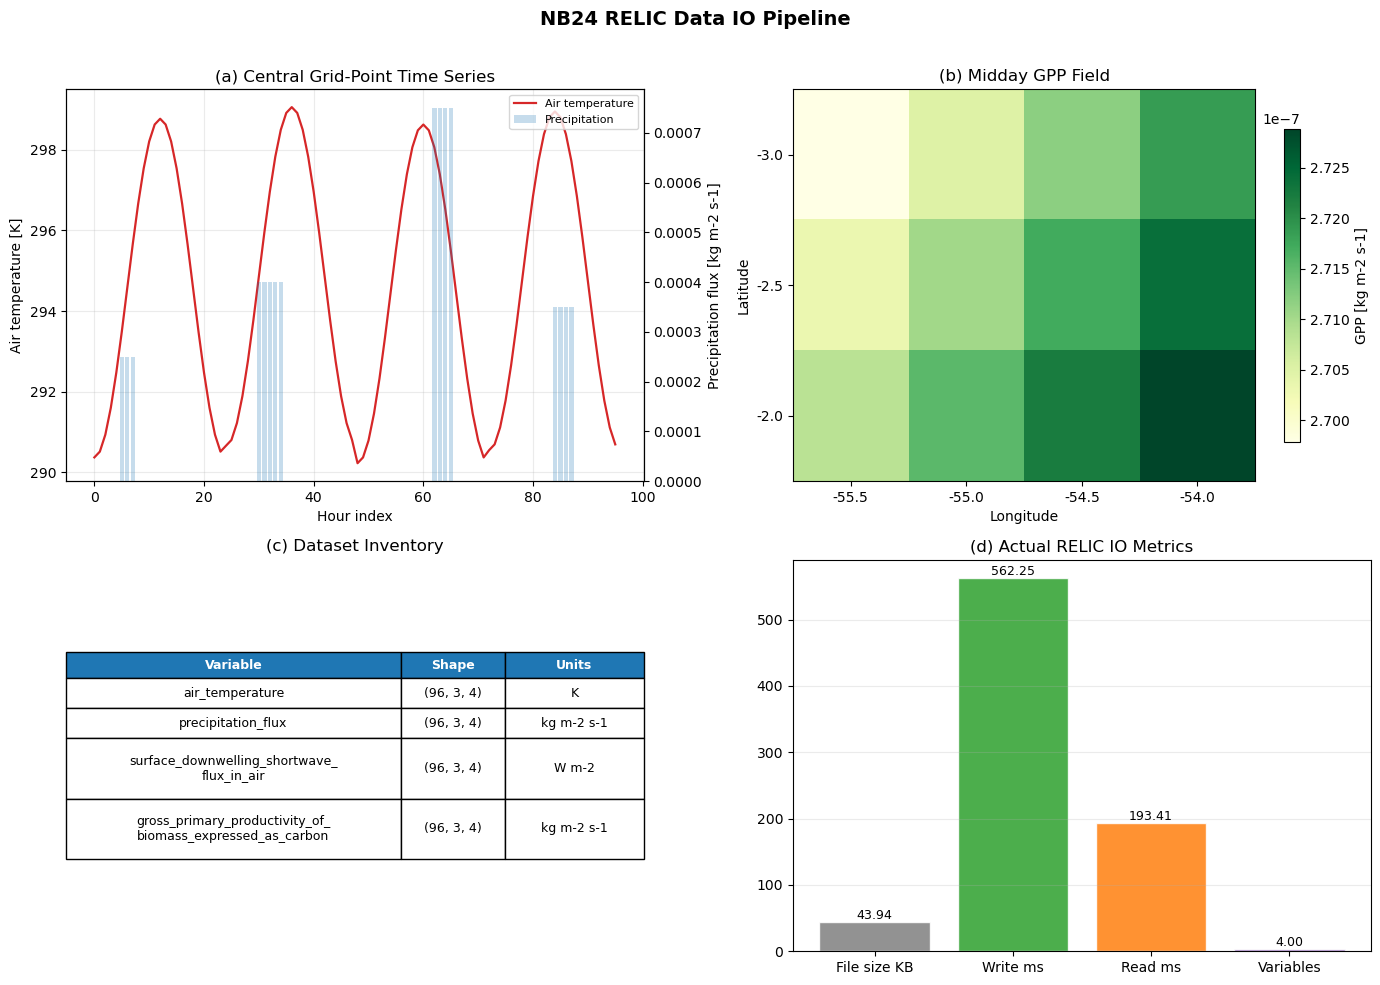

[OK] Data IO pipeline visualization generated


In [7]:
# === NB24: Data IO Pipeline Visualization ===
print("=== Data Pipeline Visualization ===")

plot_time = list(range(nb24_dataset.sizes["time"]))
center_temp = torch.as_tensor(nb24_dataset["air_temperature"].isel(lat=1, lon=1).values, dtype=torch.float32)
center_precip = torch.as_tensor(nb24_dataset["precipitation_flux"].isel(lat=1, lon=1).values, dtype=torch.float32)
midday_gpp = torch.as_tensor(nb24_dataset["gross_primary_productivity_of_biomass_expressed_as_carbon"].isel(time=12).values, dtype=torch.float32)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

ax = axes[0, 0]
ax.plot(plot_time, center_temp.detach().cpu().tolist(), color="tab:red", lw=1.6, label="Air temperature")
ax2 = ax.twinx()
ax2.bar(plot_time, center_precip.detach().cpu().tolist(), color="tab:blue", alpha=0.25, label="Precipitation")
ax.set_xlabel("Hour index")
ax.set_ylabel("Air temperature [K]")
ax2.set_ylabel("Precipitation flux [kg m-2 s-1]")
ax.set_title("(a) Central Grid-Point Time Series")
ax.grid(True, alpha=0.25)
handles_a, labels_a = ax.get_legend_handles_labels()
handles_b, labels_b = ax2.get_legend_handles_labels()
ax.legend(handles_a + handles_b, labels_a + labels_b, fontsize=8, loc="upper right")

ax = axes[0, 1]
image = ax.imshow(midday_gpp.detach().cpu(), cmap="YlGn", aspect="auto")
ax.set_xticks(range(len(lon_coord)), labels=[f"{x:.1f}" for x in lon_coord])
ax.set_yticks(range(len(lat_coord)), labels=[f"{y:.1f}" for y in lat_coord])
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("(b) Midday GPP Field")
fig.colorbar(image, ax=ax, shrink=0.8, label="GPP [kg m-2 s-1]")

ax = axes[1, 0]
import textwrap
variable_rows = []
for variable_name in nb24_dataset.data_vars:
    data_array = nb24_dataset[variable_name]
    variable_rows.append([
        "\n".join(textwrap.wrap(variable_name, width=30, break_long_words=True, break_on_hyphens=False)),
        str(tuple(int(nb24_dataset.sizes[dim]) for dim in data_array.dims)),
        data_array.attrs.get("units", ""),
    ])
table = ax.table(cellText=variable_rows, colLabels=["Variable", "Shape", "Units"], loc="center", cellLoc="center", colWidths=[0.58, 0.18, 0.24])
table.scale(1, 1.4)
table.auto_set_font_size(False)
table.set_fontsize(9)
# Wrap full CF names for display; no name or dataset key is truncated.
base_row_height = table[(1, 0)].get_height()
for row_index, row_values in enumerate(variable_rows, start=1):
    line_count = row_values[0].count("\n") + 1
    for col_index in range(3):
        table[(row_index, col_index)].set_height(base_row_height * line_count * 1.15)
for col_index in range(3):
    table[(0, col_index)].set_facecolor("#1f77b4")
    table[(0, col_index)].set_text_props(color="white", fontweight="bold")
ax.axis("off")
ax.set_title("(c) Dataset Inventory")

ax = axes[1, 1]
metric_names = ["File size KB", "Write ms", "Read ms", "Variables"]
metric_values = [
    nb24_write_result.file_size / 1024.0,
    nb24_write_result.write_time * 1000.0,
    nb24_read_result.load_time * 1000.0,
    float(len(nb24_dataset.data_vars)),
]
bar_colors = ["#7f7f7f", "#2ca02c", "#ff7f0e", "#9467bd"]
bars = ax.bar(metric_names, metric_values, color=bar_colors, alpha=0.85, edgecolor="white")
ax.set_title("(d) Actual RELIC IO Metrics")
ax.grid(True, alpha=0.25, axis="y")
for bar, value in zip(bars, metric_values):
    ax.text(bar.get_x() + bar.get_width() / 2.0, bar.get_height(), f"{value:.2f}", ha="center", va="bottom", fontsize=9)

plt.suptitle("NB24 RELIC Data IO Pipeline", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()
print("[OK] Data IO pipeline visualization generated")


In [8]:
# Examine DataIO unified adapter
print("=== DataIO Unified Adapter ===")

io_adapter = DataIO(
    reader_config=ReadConfig(cf_validate=True, cf_standardize=True, process_time=True, time_bounds=True),
    writer_config=WriteConfig(title="NB24 DataIO adapter demo", institution="RELIC tutorial", source="NB24 DataIO adapter"),
)
with warnings.catch_warnings(record=True) as adapter_info_warnings:
    warnings.simplefilter("always", FutureWarning)
    adapter_file_info = io_adapter.get_file_info(NB24_DATASET_PATH)

adapter_warning_messages = sorted({str(item.message) for item in adapter_info_warnings})
print(f"  Supported formats: {io_adapter.list_formats()}")
print(f"  File info: {adapter_file_info}")
print(f"  Performance stats: {io_adapter.get_performance_stats()}")
print(f"  Adapter warning count: {len(adapter_warning_messages)}")
for message in adapter_warning_messages[:2]:
    print(f"  adapter warning: {message}")
print("\n[OK] Data IO pipeline tutorial complete")


=== DataIO Unified Adapter ===
  Supported formats: {'read_formats': ['netcdf4', 'netcdf3', 'hdf5', 'zarr', 'csv'], 'write_formats': ['netcdf4', 'netcdf3', 'zarr', 'csv'], 'compression_methods': ['none', 'zlib', 'gzip', 'zstd', 'blosc'], 'chunking_strategies': ['auto', 'time_first', 'spatial_first', 'custom']}
  File info: {'path': './workspace', 'size_bytes': 44995, 'format': 'netcdf', 'variables': ['air_temperature', 'precipitation_flux', 'surface_downwelling_shortwave_flux_in_air', 'gross_primary_productivity_of_biomass_expressed_as_carbon'], 'dimensions': {'time': 96, 'lat': 3, 'lon': 4}, 'coordinates': ['lat', 'lon', 'time'], 'global_attributes': {'creation_date': '2026-09-30T17:02:10.226184Z', 'title': 'NB24 CF demonstration dataset', 'institution': 'RELIC tutorial', 'source': 'NB24 in-notebook tensor dataset', 'history': 'Created in NB24 and synchronized through CFConventions; 2026-09-30 17:02:10 UTC: Processed by RELIC DataWriter', 'comment': 'Written by RELIC DataWriter during

---
## Part 2: Temporal Scaling Theory

> **Reference:** `docs/source/theory/time_scaling.md`
>
> Temporal scaling converts data between temporal resolutions using explicit
> coordinates, half-open interval bounds, and a declared `temporal_semantics`.
> It writes a bounded CF cell-method and time-metadata subset.
> The operators live in `relic/coupling/scales/temporal/`
> (`TemporalAggregator`, `TemporalDisaggregator`, `QualityController`).

### 2.1 Time Weight Computation

The foundation of temporal scaling is the overlap-based target-fraction weight:

$$w_{ij} = \frac{\text{overlap}(I_i, J_j)}{\text{duration}(J_j)}$$

where:

$$\text{overlap}(I_i, J_j) = \max(0, \min(t_i^+, T_j^+) - \max(t_i^-, T_j^-))$$

**Geometric coverage:** $C^{\mathrm{geom}}_j = \sum_i w_{ij} \le 1$; it equals 1 when the source bounds cover the whole target interval. It is a support diagnostic, not a conservation law.

**Valid coverage:** $C^{\mathrm{valid}}_j = \sum_i v_i w_{ij}$ with $v_i = 0$ for missing source values. `TemporalAggregator` computes `valid_mask` as $C^{\mathrm{valid}}_j \ge \theta$, where $\theta$ is the parameter `coupling.scales.temporal.coverage_threshold` (current value 0.8). For `AggregationMethod` `MEAN`, `TIME_WEIGHTED_MEAN`, `SUM`, `MEDIAN`, `VARIANCE` and `STANDARD_DEVIATION`, targets outside `valid_mask` are NaN. For `MINIMUM`, `MAXIMUM` and `RANGE`, a target keeps its value whenever $C^{\mathrm{valid}}_j > 0$ and is NaN only when $C^{\mathrm{valid}}_j = 0$; coverage below $\theta$ then shows only in `quality_flags.insufficient_coverage_mask` (`~valid_mask`) and in the diagnostics count `insufficient_output_count`. `PERCENTILE` is rejected with a `ValueError`.

Weight matrix shape: (96, 16)
Geometric coverage min/max: 1.0 1.0


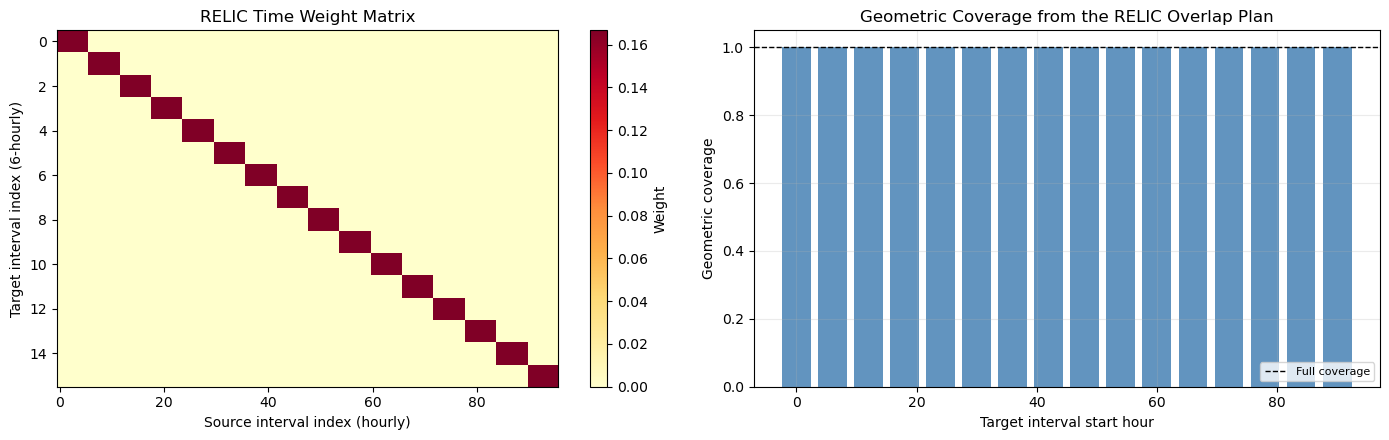

In [9]:
# === RELIC Temporal Weight Computation ===
# References:
#   RELIC temporal core and temporal aggregator APIs
# Mathematical expression:
#   w_ij = overlap(I_i, J_j) / duration(J_j) (target-fraction weight)
#   C_j = sum_i w_ij (geometric coverage of target interval j)
# Parameter meanings:
#   hourly_time_seconds: source hourly timestamps [s]
#   six_hour_time_seconds: target 6-hour timestamps [s]
#   weights_6h, coverage_6h: target fractions and geometric coverage of the RELIC overlap plan

from relic.coupling.scales.temporal.types import TemporalConfig, TemporalSemantics, ScalingDirection, ConservationLevel
from relic.coupling.scales.types import SpatialQuantityBasis
from relic.coupling.scales.temporal.aggregator import TemporalAggregator, AggregationConfig, AggregationMethod
from relic.coupling.scales.temporal.disaggregator import (
    TemporalDisaggregator,
    DisaggregationConfig,
    DisaggregationMethod,
)
from relic.coupling.scales.temporal.core import CFTimeProcessor, TimeCoordinate, TimeWeightGenerator, get_supported_calendar_names
from relic.coupling.scales.temporal.quality_control import (
    GapFiller,
    QualityConfig,
    QualityController,
)

TIME_UNITS_SECONDS = "seconds since 2001-07-01 00:00:00"
hourly_time_hours = torch.arange(nb24_dataset.sizes["time"], dtype=torch.float32)
hourly_time_seconds = hourly_time_hours * 3600.0
six_hour_time_seconds = torch.arange(0, int(hourly_time_hours.numel()), 6, dtype=torch.float32) * 3600.0
hourly_bounds = torch.stack([hourly_time_seconds, hourly_time_seconds + 3600.0], dim=1)
six_hour_bounds = torch.stack([six_hour_time_seconds, six_hour_time_seconds + 21600.0], dim=1)

source_time_coordinate = TimeCoordinate(
    values=hourly_time_seconds,
    bounds=hourly_bounds,
    units=TIME_UNITS_SECONDS,
    calendar="noleap",
)
target_time_coordinate = TimeCoordinate(
    values=six_hour_time_seconds,
    bounds=six_hour_bounds,
    units=TIME_UNITS_SECONDS,
    calendar="noleap",
)
time_weight_generator = TimeWeightGenerator(device=torch.device("cpu"))
overlap_plan_6h = time_weight_generator.build_overlap_plan(
    source_time_coordinate,
    target_time_coordinate,
)
weights_6h = overlap_plan_6h.target_fractions
coverage_6h = overlap_plan_6h.geometric_target_coverage

print("Weight matrix shape:", tuple(weights_6h.shape))
print("Geometric coverage min/max:", float(coverage_6h.min()), float(coverage_6h.max()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
image = axes[0].imshow(weights_6h.detach().cpu().T, aspect="auto", cmap="YlOrRd")
axes[0].set_xlabel("Source interval index (hourly)")
axes[0].set_ylabel("Target interval index (6-hourly)")
axes[0].set_title("RELIC Time Weight Matrix")
fig.colorbar(image, ax=axes[0], label="Weight")

coverage_x = (six_hour_time_seconds / 3600.0).detach().cpu().tolist()
axes[1].bar(coverage_x, coverage_6h.detach().cpu().tolist(), width=4.8, color="steelblue", alpha=0.85)
axes[1].axhline(1.0, color="black", ls="--", lw=1.0, label="Full coverage")
axes[1].set_xlabel("Target interval start hour")
axes[1].set_ylabel("Geometric coverage")
axes[1].set_title("Geometric Coverage from the RELIC Overlap Plan")
axes[1].grid(True, alpha=0.25)
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

### 2.2 Temporal Aggregation by Temporal Semantics

The temporal law is chosen by the explicit `temporal_semantics`, not by an intensive/extensive label. `TemporalConfig.spatial_basis` (a `SpatialQuantityBasis`: `intensive`, `cell_total`, `area_density`, or `categorical`) only records the spatial representation; the temporal operators use it to reject `categorical` fields, and the ambiguous string `extensive` raises.

With overlap duration $O_{ij}$ and validity mask $v_i$:

**Interval mean** (`interval_mean`, e.g. air temperature with `spatial_basis=intensive`): mean over the observed support

$$\bar{\phi}_j = \frac{\sum_i v_i O_{ij} \phi_i}{\sum_i v_i O_{ij}}$$

**Rate integrated to an amount** (`rate` with method `sum`, e.g. precipitation flux in kg m-2 s-1 with `spatial_basis=area_density`):

$$A_j = s_\tau \sum_i v_i O_{ij} r_i$$

where $s_\tau$ converts the coordinate time unit to `integration_time_unit`. With complete valid coverage the target amounts sum to the source amount; missing parts are not scaled up.

Precipitation amount conservation [kg m-2]: 25.73999786376953 25.740001678466797 3.814697265625e-06


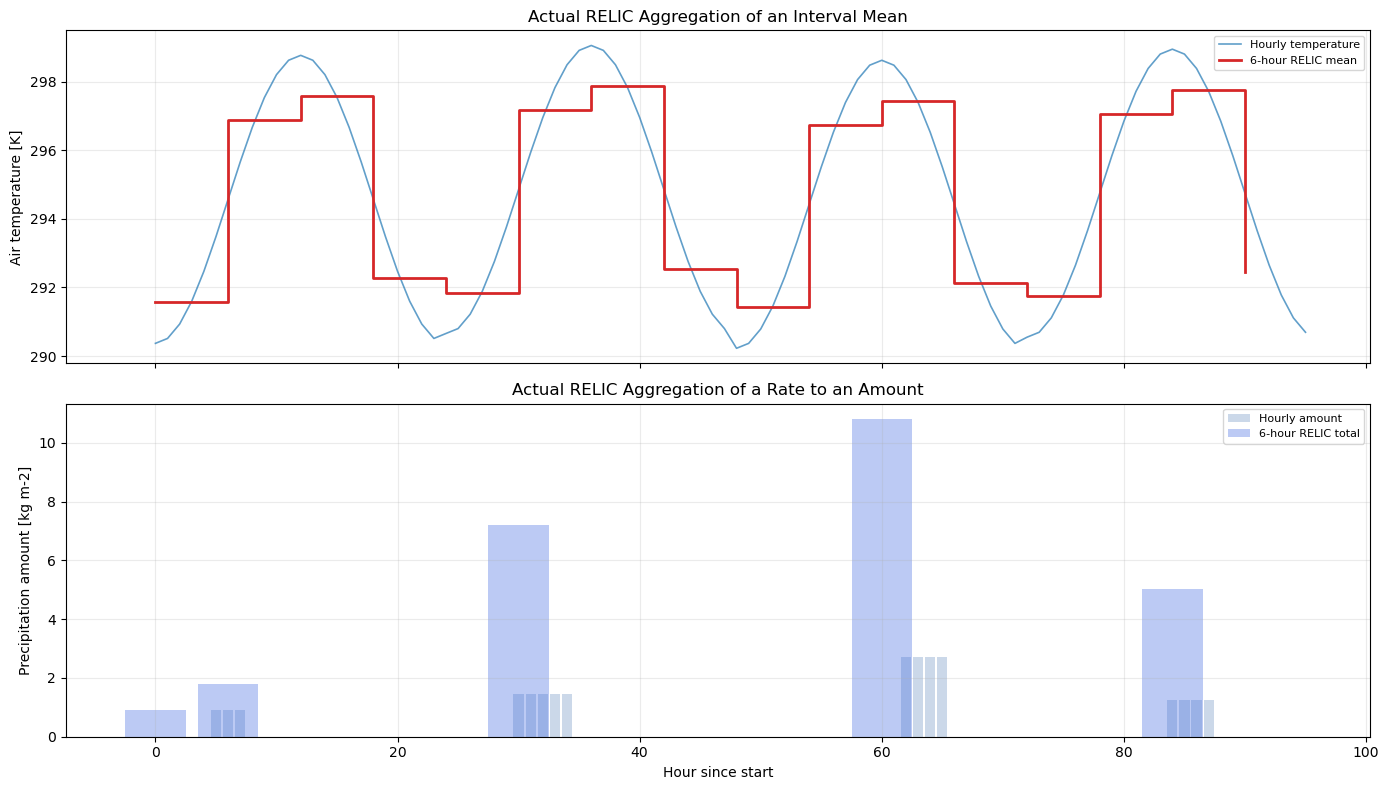

In [10]:
# === RELIC Aggregation: Interval Mean and Rate-to-Amount ===
# References:
#   RELIC TemporalAggregator
# Mathematical expression:
#   Interval mean: x_bar_j = sum_i(v_i O_ij x_i) / sum_i(v_i O_ij)
#   Rate integrated to an amount: X_j = s_tau * sum_i(v_i O_ij r_i)
# Parameter meanings:
#   hourly_temperature_center: central-grid hourly temperature [K]
#   hourly_precipitation_center: central-grid hourly precipitation flux [kg m-2 s-1]
#   precipitation_6h_total: 6-hour accumulated precipitation amount [kg m-2]

hourly_temperature_center = torch.as_tensor(nb24_dataset["air_temperature"].isel(lat=1, lon=1).values, dtype=torch.float32)
hourly_precipitation_center = torch.as_tensor(nb24_dataset["precipitation_flux"].isel(lat=1, lon=1).values, dtype=torch.float32)

temperature_6h_aggregator = TemporalAggregator(
    TemporalConfig(
        source_frequency="hourly",
        target_frequency="6hourly",
        direction=ScalingDirection.UPSCALE,
        spatial_basis=SpatialQuantityBasis.INTENSIVE,
        temporal_semantics=TemporalSemantics.INTERVAL_MEAN,
        conservation_level=ConservationLevel.NONE,
        device=torch.device("cpu"),
    ),
    AggregationConfig(method=AggregationMethod.TIME_WEIGHTED_MEAN, time_dim=-1),
)
precipitation_6h_aggregator = TemporalAggregator(
    TemporalConfig(
        source_frequency="hourly",
        target_frequency="6hourly",
        direction=ScalingDirection.UPSCALE,
        spatial_basis=SpatialQuantityBasis.AREA_DENSITY,  # kg m-2 s-1 is an amount per unit area
        temporal_semantics=TemporalSemantics.RATE,
        conservation_level=ConservationLevel.NONE,
        device=torch.device("cpu"),
    ),
    AggregationConfig(method=AggregationMethod.SUM, time_dim=-1),
)

temperature_6h_result = temperature_6h_aggregator.aggregate(
    hourly_temperature_center,
    hourly_time_seconds,
    six_hour_time_seconds,
    variable_name="air_temperature",
    standard_name="air_temperature",
    units="K",
    cell_methods="time: point",
    time_units=TIME_UNITS_SECONDS,
    calendar="noleap",
    source_bounds=hourly_bounds,
    target_bounds=six_hour_bounds,
    target_units="K",
    measure_units="K s",
    integration_time_unit="s",
)
precipitation_6h_result = precipitation_6h_aggregator.aggregate(
    hourly_precipitation_center,
    hourly_time_seconds,
    six_hour_time_seconds,
    variable_name="precipitation_flux",
    standard_name="precipitation_flux",
    units="kg m-2 s-1",
    cell_methods="time: sum",
    time_units=TIME_UNITS_SECONDS,
    calendar="noleap",
    source_bounds=hourly_bounds,
    target_bounds=six_hour_bounds,
    target_units="kg m-2",
    measure_units="kg m-2",
    integration_time_unit="s",
)

temperature_6h_mean = torch.as_tensor(temperature_6h_result.data, dtype=torch.float32).reshape(-1)
precipitation_6h_total = torch.as_tensor(precipitation_6h_result.data, dtype=torch.float32).reshape(-1)
source_precip_amount = hourly_precipitation_center * 3600.0
precip_conservation_error = torch.abs(source_precip_amount.sum() - precipitation_6h_total.sum())

print(
    "Precipitation amount conservation [kg m-2]:",
    float(source_precip_amount.sum()),
    float(precipitation_6h_total.sum()),
    float(precip_conservation_error),
)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

hour_axis = (hourly_time_seconds / 3600.0).detach().cpu().tolist()
six_hour_axis = (six_hour_time_seconds / 3600.0).detach().cpu().tolist()

axes[0].plot(hour_axis, hourly_temperature_center.detach().cpu().tolist(), color="tab:blue", lw=1.2, alpha=0.7, label="Hourly temperature")
axes[0].step(
    six_hour_axis,
    temperature_6h_mean.detach().cpu().tolist(),
    where="post",
    color="tab:red",
    lw=2.0,
    label="6-hour RELIC mean",
)
axes[0].set_ylabel("Air temperature [K]")
axes[0].set_title("Actual RELIC Aggregation of an Interval Mean")
axes[0].grid(True, alpha=0.25)
axes[0].legend(fontsize=8, loc="best")

axes[1].bar(hour_axis, source_precip_amount.detach().cpu().tolist(), width=0.85, color="lightsteelblue", alpha=0.65, label="Hourly amount")
axes[1].bar(six_hour_axis, precipitation_6h_total.detach().cpu().tolist(), width=5.0, color="royalblue", alpha=0.35, label="6-hour RELIC total")
axes[1].set_xlabel("Hour since start")
axes[1].set_ylabel("Precipitation amount [kg m-2]")
axes[1].set_title("Actual RELIC Aggregation of a Rate to an Amount")
axes[1].grid(True, alpha=0.25)
axes[1].legend(fontsize=8, loc="best")
plt.tight_layout()
plt.show()

### 2.3 Temporal Disaggregation

`TemporalDisaggregator` maps coarse intervals $j$ to fine intervals $i$ through the same overlap kernel ($O_{ji}$ overlap duration, $\Delta_j$ coarse duration). The configuration must declare `direction=DOWNSCALE`. Only `DisaggregationMethod.UNIFORM` (piecewise-constant reconstruction) runs:

**Interval mean or rate:** each fine interval takes the observed-support mean of the coarse values that cover it

$$\phi_i = \frac{\sum_j v_j O_{ji} \Phi_j}{\sum_j v_j O_{ji}}$$

**Interval accumulation:** the amount is split in proportion to overlap duration

$$a_i = \sum_j v_j \frac{O_{ji}}{\Delta_j} A_j$$

which equals $A_j / n_j$ when the $n_j$ fine intervals of coarse interval $j$ have equal durations.

`LINEAR`, `SHAPE_PRESERVING_SPLINE`, `CUBIC_SPLINE`, `CLIMATOLOGY_DIURNAL`, `EXTERNAL_DRIVER`, and `STOCHASTIC` raise `ValueError`: linear interpolation, shape-function profiles, splines, and stochastic reconstruction are not available. `DisaggregationConfig` has only `method`, `allow_negative`, `use_physical_constraints`, and `time_dim`.

Daily source energy [J m-2]: [27386144.0, 32148952.0, 25004738.0, 30362896.0]
Daily reconstructed energy [J m-2]: [27386144.0, 32148956.0, 25004738.0, 30362898.0]
Shortwave reconstruction RMSE [W m-2]: 235.7342987060547


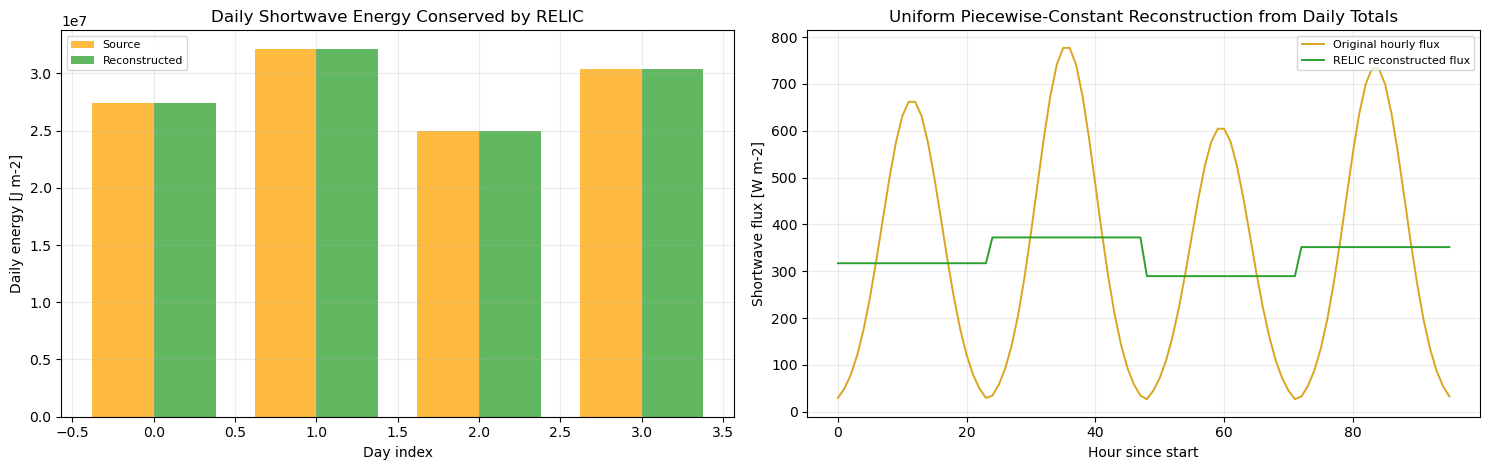

In [11]:
# === RELIC Temporal Disaggregation with Supported Uniform Reconstruction ===
# References:
#   RELIC TemporalAggregator and TemporalDisaggregator
# Mathematical expression:
#   Daily total E_d is distributed uniformly to covered hourly intervals: e_h = E_d / N_h
# Parameter meanings:
#   daily_shortwave_energy: daily integrated shortwave energy [J m-2]
#   reconstructed_shortwave_flux: hourly equivalent flux reconstructed by RELIC [W m-2]
#   spatial_basis=AREA_DENSITY: J m-2 s-1 and J m-2 are amounts per unit area

hourly_shortwave_center = torch.as_tensor(
    nb24_dataset["surface_downwelling_shortwave_flux_in_air"].isel(lat=1, lon=1).values,
    dtype=torch.float32,
)
daily_time_seconds = torch.arange(0, int(hourly_time_hours.numel()), 24, dtype=torch.float32) * 3600.0 + 43200.0
daily_bounds = torch.stack([daily_time_seconds - 43200.0, daily_time_seconds + 43200.0], dim=1)

daily_shortwave_aggregator = TemporalAggregator(
    TemporalConfig(
        source_frequency="hourly",
        target_frequency="daily",
        direction=ScalingDirection.UPSCALE,
        spatial_basis=SpatialQuantityBasis.AREA_DENSITY,
        temporal_semantics=TemporalSemantics.RATE,
        conservation_level=ConservationLevel.NONE,
        device=torch.device("cpu"),
    ),
    AggregationConfig(method=AggregationMethod.SUM, time_dim=-1),
)
shortwave_disaggregator = TemporalDisaggregator(
    TemporalConfig(
        source_frequency="daily",
        target_frequency="hourly",
        direction=ScalingDirection.DOWNSCALE,
        spatial_basis=SpatialQuantityBasis.AREA_DENSITY,
        temporal_semantics=TemporalSemantics.INTERVAL_ACCUMULATION,
        conservation_level=ConservationLevel.NONE,
        device=torch.device("cpu"),
    ),
    DisaggregationConfig(
        method=DisaggregationMethod.UNIFORM,
        time_dim=-1,
    ),
)

daily_shortwave_energy = daily_shortwave_aggregator.aggregate(
    hourly_shortwave_center,
    hourly_time_seconds,
    daily_time_seconds,
    variable_name="surface_downwelling_shortwave_flux_in_air",
    standard_name="surface_downwelling_shortwave_flux_in_air",
    units="J m-2 s-1",
    cell_methods="time: point",
    time_units=TIME_UNITS_SECONDS,
    calendar="noleap",
    source_bounds=hourly_bounds,
    target_bounds=daily_bounds,
    target_units="J m-2",
    measure_units="J m-2",
    integration_time_unit="s",
)
reconstructed_hourly_energy = shortwave_disaggregator.disaggregate(
    daily_shortwave_energy.data,
    daily_time_seconds,
    hourly_time_seconds,
    variable_name="surface_downwelling_shortwave_flux_in_air",
    standard_name="surface_downwelling_shortwave_flux_in_air",
    units="J m-2",
    cell_methods="time: sum",
    time_units=TIME_UNITS_SECONDS,
    calendar="noleap",
    source_bounds=daily_bounds,
    target_bounds=hourly_bounds,
    target_units="J m-2",
    measure_units="J m-2",
)
reconstructed_shortwave_flux = torch.as_tensor(reconstructed_hourly_energy.data, dtype=torch.float32).reshape(-1) / 3600.0
shortwave_residual = reconstructed_shortwave_flux - hourly_shortwave_center
daily_source_energy = (hourly_shortwave_center.reshape(-1, 24) * 3600.0).sum(dim=1)
daily_reconstructed_energy = torch.as_tensor(reconstructed_hourly_energy.data, dtype=torch.float32).reshape(-1, 24).sum(dim=1)
shortwave_rmse = torch.sqrt(torch.mean(shortwave_residual ** 2))

print("Daily source energy [J m-2]:", daily_source_energy.detach().cpu().tolist())
print("Daily reconstructed energy [J m-2]:", daily_reconstructed_energy.detach().cpu().tolist())
print("Shortwave reconstruction RMSE [W m-2]:", float(shortwave_rmse))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

daily_axis = list(range(len(daily_source_energy)))
bar_width = 0.38
axes[0].bar([x - bar_width / 2.0 for x in daily_axis], daily_source_energy.detach().cpu().tolist(), width=bar_width, color="orange", alpha=0.75, label="Source")
axes[0].bar([x + bar_width / 2.0 for x in daily_axis], daily_reconstructed_energy.detach().cpu().tolist(), width=bar_width, color="tab:green", alpha=0.75, label="Reconstructed")
axes[0].set_xlabel("Day index")
axes[0].set_ylabel("Daily energy [J m-2]")
axes[0].set_title("Daily Shortwave Energy Conserved by RELIC")
axes[0].grid(True, alpha=0.25)
axes[0].legend(fontsize=8, loc="best")

axes[1].plot(hour_axis, hourly_shortwave_center.detach().cpu().tolist(), color="goldenrod", lw=1.4, label="Original hourly flux")
axes[1].plot(hour_axis, reconstructed_shortwave_flux.detach().cpu().tolist(), color="tab:green", lw=1.4, label="RELIC reconstructed flux")
axes[1].set_xlabel("Hour since start")
axes[1].set_ylabel("Shortwave flux [W m-2]")
axes[1].set_title("Uniform Piecewise-Constant Reconstruction from Daily Totals")
axes[1].grid(True, alpha=0.25)
axes[1].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

### 2.4 Calendar Systems

The calendar definitions (`get_supported_calendar_names()`, read from the parameter
database) contain the eight names below; `CFTimeProcessor` also normalizes the CF name
`standard` to `gregorian`. The temporal mapping operators (`TemporalAggregator`, `TemporalDisaggregator`) currently accept only `noleap` and `360_day`, with the same calendar and reference time for source and target; other data must be converted and bounded explicitly before mapping.

| Calendar | Days/Year | Leap Rule | Description |
|---|:---:|---|---|
| `gregorian` | 365.25 | Standard | Standard calendar with leap years |
| `proleptic_gregorian` | 365.25 | Extended | Gregorian extended before 1582 |
| `julian` | 365.25 | Every 4 years | Julian calendar |
| `noleap` | 365.0 | None | No leap years (365 days/year) |
| `365_day` | 365.0 | None | Alias of `noleap` |
| `all_leap` | 366.0 | Every year | Every year has 366 days |
| `366_day` | 366.0 | Every year | Alias of `all_leap` |
| `360_day` | 360.0 | Artificial | Idealized 360-day year (12x30) |

**Time bounds:** `CFTimeProcessor.create_time_bounds` builds centred bounds for regular intervals:
$$\text{bounds}[i] = [t_i - \Delta t / 2, \; t_i + \Delta t / 2]$$
The mapping operators never call it and never infer bounds; pass explicit half-open bounds.

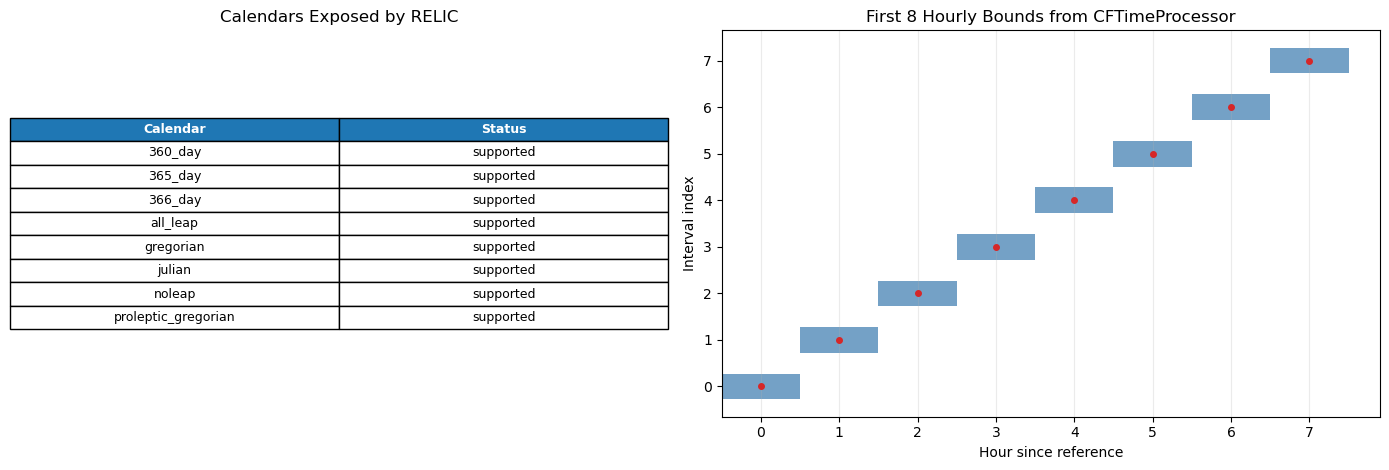

In [12]:
# === RELIC Calendar Support and Time Bounds ===
# References:
#   RELIC temporal core and CF time processor
# Mathematical expression:
#   Bounds are generated around each timestamp in the declared calendar and units system
# Parameter meanings:
#   supported_calendars: calendars exposed by RELIC temporal core
#   hourly_bounds_cf: time bounds computed by RELIC CFTimeProcessor

cf_time_processor = CFTimeProcessor()
supported_calendars = get_supported_calendar_names()

hourly_time_coord = TimeCoordinate(
    values=hourly_time_hours,
    units=TIME_UNITS_NB24,
    calendar="gregorian",
)
hourly_bounds_cf = cf_time_processor.create_time_bounds(hourly_time_coord, "H")

calendar_table_rows = []
for calendar_name in supported_calendars:
    calendar_table_rows.append([calendar_name, "supported"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

table = axes[0].table(
    cellText=calendar_table_rows,
    colLabels=["Calendar", "Status"],
    loc="center",
    cellLoc="center",
)
table.scale(1.0, 1.35)
table.auto_set_font_size(False)
table.set_fontsize(9)
for col_index in range(2):
    table[(0, col_index)].set_facecolor("#1f77b4")
    table[(0, col_index)].set_text_props(color="white", fontweight="bold")
axes[0].axis("off")
axes[0].set_title("Calendars Exposed by RELIC")

for idx in range(8):
    left = float(hourly_bounds_cf[idx, 0].item())
    width = float((hourly_bounds_cf[idx, 1] - hourly_bounds_cf[idx, 0]).item())
    center = float(hourly_time_hours[idx].item())
    axes[1].barh(idx, width, left=left, height=0.55, color="steelblue", alpha=0.75)
    axes[1].plot(center, idx, marker="o", color="tab:red", markersize=4)
axes[1].set_xlabel("Hour since reference")
axes[1].set_ylabel("Interval index")
axes[1].set_title("First 8 Hourly Bounds from CFTimeProcessor")
axes[1].grid(True, alpha=0.25, axis="x")
plt.tight_layout()
plt.show()

### 2.5 Quality Control & Coverage Assessment

`QualityController()` reads every threshold from the parameter database through `QualityConfig.from_parameter_manager()`: `coupling.scales.temporal.coverage_threshold` and `coupling.scales.temporal.quality_control.*`. `QualityConfig` has no Python defaults.

**Quality Levels** ($f$ = valid or unflagged sample fraction; current parameter values):

| Level | Fraction | Longest missing run | Parameters |
|---|:---:|---|---|
| Excellent | $f \ge 0.95$ | $\le 1$ sample | `grade_excellent_min_fraction`, `grade_excellent_max_gap_length` |
| Good | $f \ge 0.8$ | $\le 7$ samples | `grade_good_min_fraction`, `max_gap_length` |
| Acceptable | $f \ge 0.6$ | not checked | `grade_acceptable_min_fraction` |
| Poor | $f \ge 0.4$ | not checked | `grade_poor_min_fraction` |
| Unacceptable | $f < 0.4$ | not checked | - |

`assess_quality` flags only missing (NaN/Inf), gap-filled, and outlier samples, and its final level grades the unflagged fraction without the gap criterion. Coverage below `coverage_threshold` is a verdict on the whole series: it flags no sample, is counted in `QualityMetrics.insufficient_coverage_count`, and makes `validate_for_operation` return `False`.

**Outlier Detection** (only for series with at least `outlier_min_valid_samples` = 10 finite samples):

- Z-Score: $z_i = (\phi_i - \bar{\phi}) / \sigma_\phi$, outlier if $\lvert z_i \rvert > \theta_z$ with $\theta_z$ = `outlier_threshold` = 3.0
- Modified Z-Score (robust): $M_i = 0.6745 \cdot (\phi_i - \tilde{\phi}) / \text{MAD}$, outlier if $\lvert M_i \rvert > \theta_z$
- IQR: outlier if $\phi_i < Q_1 - k \cdot \text{IQR}$ or $\phi_i > Q_3 + k \cdot \text{IQR}$ with $k$ = `iqr_fence_factor` = 1.5

QC parameters: coverage_threshold=0.8 max_gap_length=7 gap_filling_method=linear outlier_method=zscore outlier_threshold=3.0
Coverage fraction: 0.906
Gap count: 4
Max gap length: 4
Interpolated values: 9
Quality level: good
Series below coverage threshold: 0


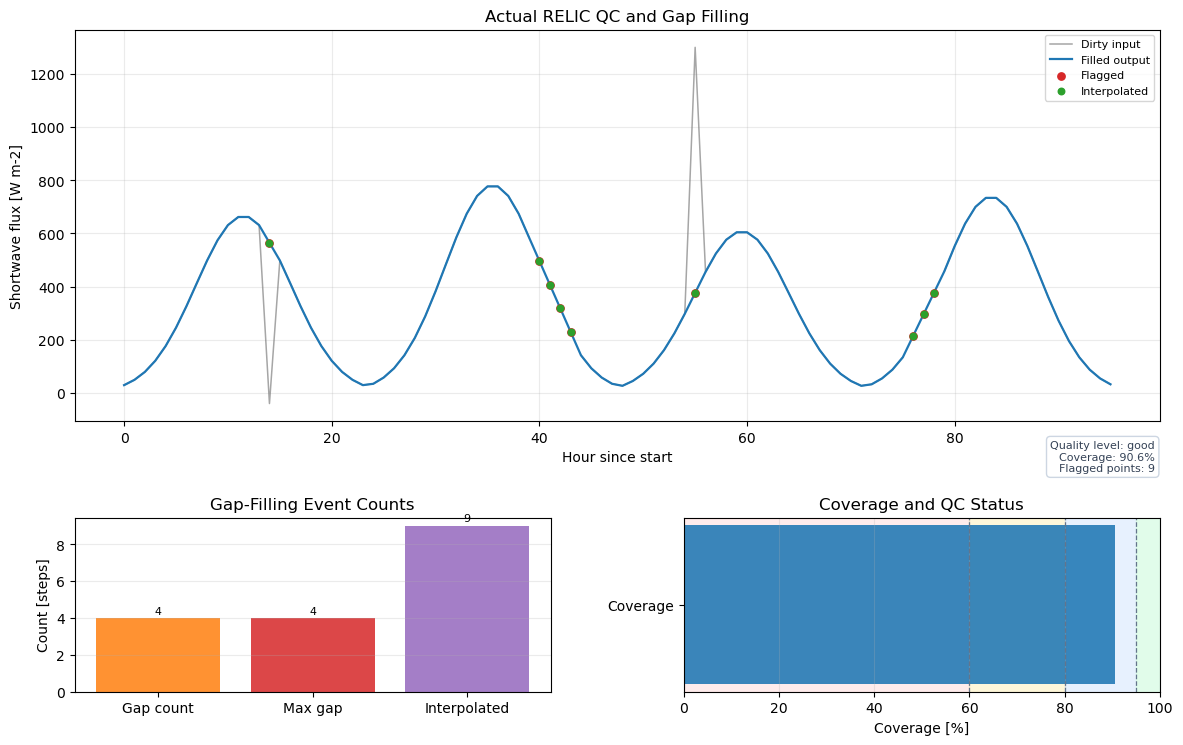

In [13]:
# === RELIC Quality Control and Gap Filling ===
# References:
#   RELIC temporal quality control module
# Mathematical expression:
#   Outlier detection and gap filling are executed by QualityController and GapFiller
#   with thresholds read from the parameter database (QualityConfig.from_parameter_manager)
# Parameter meanings:
#   qc_shortwave_dirty: shortwave series with injected faults
#   qc_shortwave_filled: RELIC gap-filled shortwave series

qc_shortwave_dirty = hourly_shortwave_center.clone()
qc_shortwave_dirty[14] = -40.0
qc_shortwave_dirty[55] = 1300.0
qc_shortwave_dirty[40:44] = float("nan")
qc_shortwave_dirty[76:79] = float("nan")

quality_config_nb24 = QualityConfig.from_parameter_manager()
quality_controller_nb24 = QualityController(quality_config_nb24)
gap_filler_nb24 = GapFiller(quality_config_nb24)
qc_time_coord = TimeCoordinate(
    values=hourly_time_seconds,
    units=TIME_UNITS_SECONDS,
    calendar="gregorian",
)

qc_shortwave_invalid = (
    torch.isnan(qc_shortwave_dirty)
    | (qc_shortwave_dirty < 0.0)
    | (qc_shortwave_dirty > 1100.0)
)
qc_shortwave_input = qc_shortwave_dirty.clone()
qc_shortwave_input[qc_shortwave_invalid] = float("nan")
# assess_quality returns (processed_data, quality_flags, metrics); processed_data is the
# gap-filled series, and outliers are only flagged (bit 3), never replaced.
qc_shortwave_assessed, qc_flags_temporal, qc_metrics_temporal = quality_controller_nb24.assess_quality(qc_shortwave_input, qc_time_coord)
qc_shortwave_filled, qc_interp_mask = gap_filler_nb24.fill_gaps(
    qc_shortwave_input,
    qc_time_coord,
    torch.isnan(qc_shortwave_input),
)
qc_flags_temporal.set_flag(torch.where(qc_interp_mask)[0], 2)

print(
    "QC parameters:",
    f"coverage_threshold={quality_config_nb24.coverage_threshold}",
    f"max_gap_length={quality_config_nb24.max_gap_length}",
    f"gap_filling_method={quality_config_nb24.gap_filling_method.value}",
    f"outlier_method={quality_config_nb24.outlier_method.value}",
    f"outlier_threshold={quality_config_nb24.outlier_threshold}",
)
print(f"Coverage fraction: {qc_metrics_temporal.coverage_fraction:.3f}")
print(f"Gap count: {qc_metrics_temporal.gap_count}")
print(f"Max gap length: {qc_metrics_temporal.max_gap_length}")
print(f"Interpolated values: {int(qc_interp_mask.sum().item())}")
print(f"Quality level: {qc_metrics_temporal.quality_level.value}")
print(f"Series below coverage threshold: {qc_metrics_temporal.insufficient_coverage_count}")

flagged_indices = torch.where(qc_shortwave_invalid)[0].detach().cpu().tolist()
interpolated_indices = torch.where(qc_interp_mask)[0].detach().cpu().tolist()

from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(14, 8.6))
gs = GridSpec(2, 2, figure=fig, height_ratios=[2.25, 1.0], hspace=0.34, wspace=0.28)

ax_main = fig.add_subplot(gs[0, :])
ax_main.plot(hour_axis, qc_shortwave_dirty.detach().cpu().tolist(), color="gray", lw=1.1, alpha=0.7, label="Dirty input")
ax_main.plot(hour_axis, qc_shortwave_filled.detach().cpu().tolist(), color="tab:blue", lw=1.6, label="Filled output")
if flagged_indices:
    ax_main.scatter(flagged_indices, qc_shortwave_filled[torch.tensor(flagged_indices, dtype=torch.long)].detach().cpu().tolist(), color="tab:red", s=28, zorder=5, label="Flagged")
if interpolated_indices:
    ax_main.scatter(interpolated_indices, qc_shortwave_filled[torch.tensor(interpolated_indices, dtype=torch.long)].detach().cpu().tolist(), color="tab:green", s=22, zorder=6, label="Interpolated")
ax_main.set_ylabel("Shortwave flux [W m-2]")
ax_main.set_xlabel("Hour since start")
ax_main.set_title("Actual RELIC QC and Gap Filling")
ax_main.grid(True, alpha=0.25)
ax_main.legend(fontsize=8, loc="upper right")

ax_counts = fig.add_subplot(gs[1, 0])
count_labels = ["Gap count", "Max gap", "Interpolated"]
count_values = [
    float(qc_metrics_temporal.gap_count),
    float(qc_metrics_temporal.max_gap_length),
    float(qc_interp_mask.sum().item()),
]
count_colors = ["#ff7f0e", "#d62728", "#9467bd"]
count_bars = ax_counts.bar(count_labels, count_values, color=count_colors, alpha=0.85)
ax_counts.set_ylabel("Count [steps]")
ax_counts.set_title("Gap-Filling Event Counts")
ax_counts.grid(True, alpha=0.25, axis="y")
ax_counts.tick_params(axis="x", rotation=0)
for bar, value in zip(count_bars, count_values):
    ax_counts.text(bar.get_x() + bar.get_width() / 2.0, value + 0.12, f"{int(value)}", ha="center", va="bottom", fontsize=8)

ax_quality = fig.add_subplot(gs[1, 1])
coverage_percent = 100.0 * float(qc_metrics_temporal.coverage_fraction)
flagged_count = len(flagged_indices)
grade_acceptable_percent = 100.0 * quality_config_nb24.grade_acceptable_min_fraction
grade_good_percent = 100.0 * quality_config_nb24.grade_good_min_fraction
grade_excellent_percent = 100.0 * quality_config_nb24.grade_excellent_min_fraction
ax_quality.axvspan(0.0, grade_acceptable_percent, color="#FEE2E2", alpha=0.65)
ax_quality.axvspan(grade_acceptable_percent, grade_good_percent, color="#FEF3C7", alpha=0.65)
ax_quality.axvspan(grade_good_percent, grade_excellent_percent, color="#DBEAFE", alpha=0.65)
ax_quality.axvspan(grade_excellent_percent, 100.0, color="#DCFCE7", alpha=0.85)
ax_quality.barh([0], [coverage_percent], color="#1f77b4", alpha=0.88, height=0.45)
for threshold in [grade_acceptable_percent, grade_good_percent, grade_excellent_percent]:
    ax_quality.axvline(threshold, color="#64748B", lw=0.9, ls="--")
ax_quality.set_xlim(0.0, 100.0)
ax_quality.set_yticks([0])
ax_quality.set_yticklabels(["Coverage"])
ax_quality.set_xlabel("Coverage [%]")
ax_quality.set_title("Coverage and QC Status")
ax_quality.grid(True, alpha=0.25, axis="x")
quality_summary = chr(10).join([
    f"Quality level: {qc_metrics_temporal.quality_level.value}",
    f"Coverage: {coverage_percent:.1f}%",
    f"Flagged points: {flagged_count}",
])
ax_quality.text(99.0, 0.42, quality_summary, ha="right", va="center", fontsize=8, color="#334155", bbox={"boxstyle": "round,pad=0.35", "facecolor": "white", "edgecolor": "#CBD5E1", "alpha": 0.96})

plt.show()

### 2.6 Uncertainty and Conservation Diagnostics

The formulas below are background for user-side analysis; the RELIC temporal operators do not compute them.

**Interpolation uncertainty** scales with gap length:

$$\sigma_{\text{interp}} = \sigma_{\text{base}} \cdot \left(1 + \frac{L_{\text{gap}}}{L_{\text{ref}}}\right)$$

**Aggregation uncertainty** propagation:
- For time-weighted means: $\sigma_{\bar{\phi}}^2 = \sum_i w_{ij}^2 \sigma_{\phi_i}^2$
- For conservative sums: $\sigma_\Phi^2 = \sum_i \left(\frac{\partial\Phi}{\partial\phi_i}\right)^2 \sigma_{\phi_i}^2$

**Mapping residual:** for the interval mapping laws (`MEAN`/`TIME_WEIGHTED_MEAN` on `interval_mean` or `rate`, `SUM` on `rate` or `interval_accumulation`, and the uniform disaggregation of these semantics) a conservation level other than `none` makes the operators compute the residual $R$ between target and source measures on the accepted support and its relative value $\lvert R \rvert / \max(A, Q_{\mathrm{ref}})$, with the source activity $A = \sum \lvert q_{\mathrm{source}} \rvert$ and the reference magnitude $Q_{\mathrm{ref}}$ read from the parameter named by `q_ref_parameter` (required when the level is not `none`). `RELAXED` only reports it, `MODERATE` also compares it with `validation.conservation.conservation_tolerance` without blocking, and `STRICT` raises `ValueError` on a violation; the residual is never used to correct values. `state_at_boundary` mappings and descriptive statistics have no residual law and raise for any level other than `none`. The cells above use `conservation_level=NONE`, so the daily energy bias below is computed directly from the RELIC outputs (reconstructed minus source daily energy):

$$b_d = \sum_{h \in d} \hat{a}_h - \sum_{h \in d} \phi_h \Delta t_h$$

Daily RMSE [W m-2]: [223.72576904296875, 262.63458251953125, 204.2713165283203, 248.04376220703125]
Daily energy bias [J m-2]: [0.0, 4.0, 0.0, 2.0]
QC validation for aggregation: True


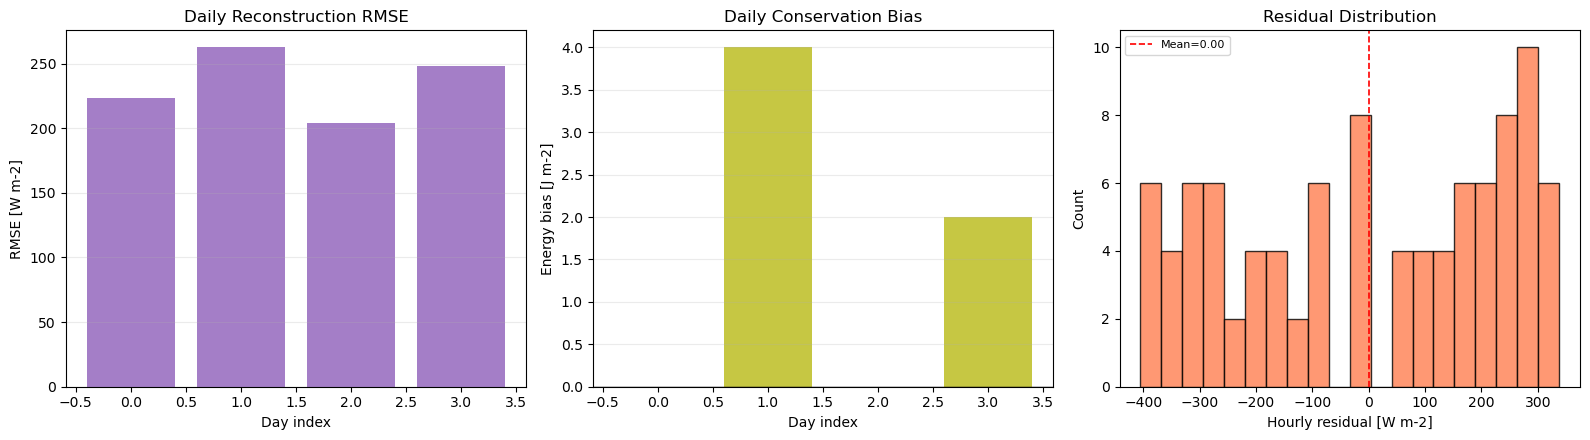

In [14]:
# === Actual RELIC Temporal Diagnostics ===
# References:
#   RELIC temporal aggregation, disaggregation, and quality-control APIs
# Mathematical expression:
#   Residual diagnostics are computed from actual RELIC outputs only
# Parameter meanings:
#   daily_shortwave_rmse: per-day reconstruction RMSE [W m-2]
#   shortwave_residual: hourly reconstruction residual [W m-2]

shortwave_residual = reconstructed_shortwave_flux - hourly_shortwave_center
daily_shortwave_rmse = torch.sqrt(torch.mean(shortwave_residual.reshape(-1, 24) ** 2, dim=1))
daily_energy_bias = daily_reconstructed_energy - daily_source_energy

print("Daily RMSE [W m-2]:", daily_shortwave_rmse.detach().cpu().tolist())
print("Daily energy bias [J m-2]:", daily_energy_bias.detach().cpu().tolist())
print("QC validation for aggregation:", quality_controller_nb24.validate_for_operation(qc_shortwave_filled, qc_time_coord, "aggregation"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].bar(daily_axis, daily_shortwave_rmse.detach().cpu().tolist(), color="tab:purple", alpha=0.85)
axes[0].set_xlabel("Day index")
axes[0].set_ylabel("RMSE [W m-2]")
axes[0].set_title("Daily Reconstruction RMSE")
axes[0].grid(True, alpha=0.25, axis="y")

axes[1].bar(daily_axis, daily_energy_bias.detach().cpu().tolist(), color="tab:olive", alpha=0.85)
axes[1].axhline(0.0, color="black", lw=1.0)
axes[1].set_xlabel("Day index")
axes[1].set_ylabel("Energy bias [J m-2]")
axes[1].set_title("Daily Conservation Bias")
axes[1].grid(True, alpha=0.25, axis="y")

axes[2].hist(shortwave_residual.detach().cpu().tolist(), bins=20, color="coral", alpha=0.8, edgecolor="black")
axes[2].axvline(float(shortwave_residual.mean()), color="red", ls="--", lw=1.2, label=f"Mean={float(shortwave_residual.mean()):.2f}")
axes[2].set_xlabel("Hourly residual [W m-2]")
axes[2].set_ylabel("Count")
axes[2].set_title("Residual Distribution")
axes[2].legend(fontsize=8, loc="best")
plt.tight_layout()
plt.show()

## Summary

| Component | Class | Purpose |
|---|---|---|
| Reader | `DataReader` | Load forcing/observation data |
| Writer | `DataWriter` | Save datasets with CF variable metadata (no dataset-level CF certification) |
| Diagnostics | `DiagnosticWriter` | Conservation summaries to CF-time datasets and NetCDF |
| Health Check | `IOHealthChecker` | Check I/O dependencies, formats, compression, CF subset, integration, performance |
| Standards | `cf_conventions` | CF standard-name (table v94) and unit validation of one variable |
| Adapter | `DataIO` | Reader and writer behind one object |
